# 1 · O problema, os dados e as características

Notebook de apresentação do TCC *Sistema de Priorização de Escolas em Risco de Evasão (PE)*.

Ele **não refaz o pipeline**: lê os arquivos que o pipeline já gerou (`data/interim/`, `data/processed/`) e chama as mesmas funções de `src/` usadas pelos scripts e pelos testes. Nada é gravado em disco.

| Seção | Slide |
|---|---|
| 1. A média esconde a concentração | 4 |
| 2. Do painel às 1.586 observações | 8 |
| 3. O que o sistema prevê | 9 |
| 4. As 39 características em 6 grupos | 10 |
| 5. Relação de cada característica com o abandono | 10 |
| 6. Os testes que travam o pipeline | 12 |

In [1]:
import logging, sys, time, warnings
from pathlib import Path

# Raiz do projeto (evasao-escolar/): sobe a partir da pasta do notebook até achar src/.
ROOT = Path.cwd()
while not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

logging.disable(logging.INFO)          # sem o log INFO do pipeline na tela
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CINZA, AZUL, VERDE, VERMELHO = "#9E9E9E", "#1565C0", "#2E7D32", "#C62828"
print("Projeto:", ROOT)

Projeto: F:\repos\evasao-escolar\evasao-escolar


## 1. A média esconde a concentração

A taxa média de abandono da rede cai ano a ano, mas o abandono se concentra em poucas escolas. Fonte: Taxas de Rendimento do INEP (`data/interim/taxas_rendimento_pe_estadual_em.parquet`).

Taxa média de abandono: {2022: '2.05%', 2023: '1.37%', 2024: '0.96%'}
2024: 791 escolas, 2,043 alunos abandonaram
Escolas sem nenhum abandono: 67%
As 79 escolas mais críticas (10%) concentram 76% dos alunos que abandonaram


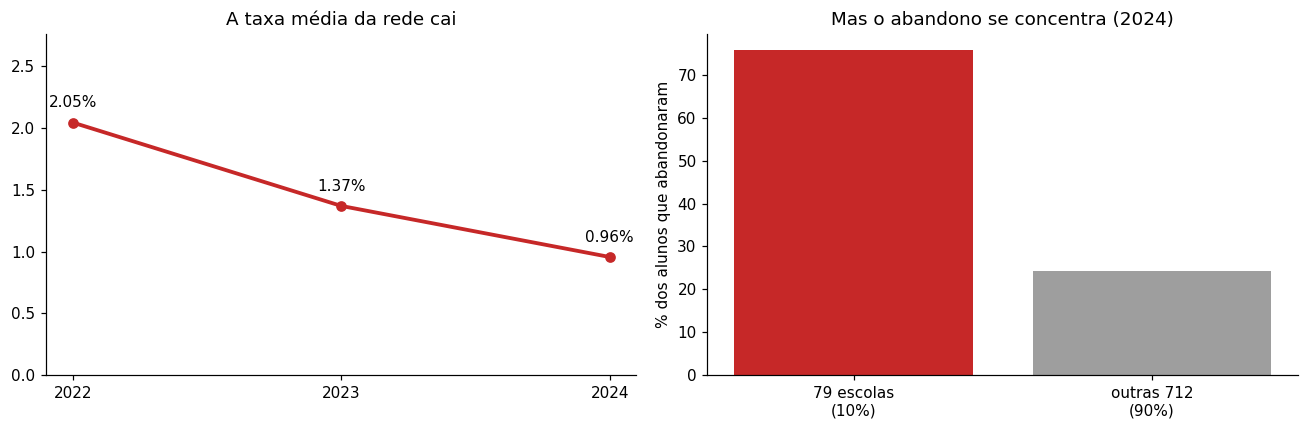

In [2]:
taxas = pd.read_parquet(ROOT / "data/interim/taxas_rendimento_pe_estadual_em.parquet")
painel = pd.read_parquet(ROOT / "data/interim/painel_escola_ano_pe_estadual_em.parquet")

media_ano = taxas.groupby("NU_ANO_CENSO")["TAXA_ABND_MED"].mean()

# Alunos que abandonaram = taxa × matrículas do EM, no ano mais recente
d24 = (taxas[taxas.NU_ANO_CENSO == 2024]
       .merge(painel.loc[painel.NU_ANO_CENSO == 2024, ["CO_ENTIDADE", "QT_MAT_MED"]], on="CO_ENTIDADE"))
d24["alunos_abandono"] = d24["TAXA_ABND_MED"] * d24["QT_MAT_MED"] / 100
d24 = d24.sort_values("alunos_abandono", ascending=False)
k = int(len(d24) * 0.10)
total = d24["alunos_abandono"].sum()
fatia = d24.head(k)["alunos_abandono"].sum() / total

print("Taxa média de abandono:", {a: f"{v:.2f}%" for a, v in media_ano.items()})
print(f"2024: {len(d24)} escolas, {total:,.0f} alunos abandonaram")
print(f"Escolas sem nenhum abandono: {(d24.TAXA_ABND_MED == 0).mean():.0%}")
print(f"As {k} escolas mais críticas (10%) concentram {fatia:.0%} dos alunos que abandonaram")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(media_ano.index, media_ano.values, "o-", color=VERMELHO, lw=2.5)
for x, y in media_ano.items():
    a1.annotate(f"{y:.2f}%", (x, y), textcoords="offset points", xytext=(0, 10), ha="center")
a1.set_xticks(media_ano.index); a1.set_ylim(0, media_ano.max() * 1.35)
a1.set_title("A taxa média da rede cai")
a2.bar([f"{k} escolas\n(10%)", f"outras {len(d24) - k}\n(90%)"], [fatia * 100, (1 - fatia) * 100],
       color=[VERMELHO, CINZA])
a2.set_ylabel("% dos alunos que abandonaram"); a2.set_title("Mas o abandono se concentra (2024)")
plt.tight_layout(); plt.show()

## 2. Do painel às 1.586 observações

O par é **características do ano t → abandono do ano t+1**. Com três anos de painel só se formam dois pares, e o último ano entra como alvo, não como origem. `rastrear_reducao_amostra()` reconstrói essa cadeia (Quadro 5), e `tests/test_rastreabilidade_amostra.py` a trava.

In [3]:
from src.features.build_features import rastrear_reducao_amostra
from src.models.train import carregar_dataset, colunas_features, TARGET_COL, ANO_COL

funil = rastrear_reducao_amostra()
display(funil)

df = carregar_dataset()
features = colunas_features(df)
print(f"Conjunto de modelagem: {len(df):,} observações | {df.CO_ENTIDADE.nunique()} escolas | "
      f"{df.CO_MUNICIPIO.nunique()} municípios | {len(features)} características")
print("Observações por ano das características:", df[ANO_COL].value_counts().sort_index().to_dict())
print("Valores ausentes nas características:", int(df[features].isna().sum().sum()))

,etapa,criterio,linhas_removidas,linhas_restantes,escolas_restantes
0,Painel histórico escola x ano,"Escolas estaduais de EM em atividade, 2022 a 2024",0,2392,806
1,"Anos que podem servir de origem (t = [2022, 20...",O ano 2024 não tem 2025 para observar: entra c...,791,1601,804
2,Pares completos (t -> t+1),Escola sem abandono observado no ano seguinte ...,15,1586,801


Conjunto de modelagem: 1,586 observações | 801 escolas | 185 municípios | 39 características
Observações por ano das características: {2022: 797, 2023: 789}
Valores ausentes nas características: 0


## 3. O que o sistema prevê

O alvo é a **taxa de abandono do ano seguinte** (`taxa_abandono_t1`). A maioria das escolas não tem abandono, e por isso prever o valor exato é tão difícil.

Observações com abandono zero: 68%
Observações acima de 10%:      2%
Abandono médio do ano seguinte: {'2022→2023': '1.36%', '2023→2024': '0.88%'}


,escolas,abandono_medio
grupo,,
Urbana,679,0.630
Rural,70,0.897
Indígena/quilombola,42,6.321


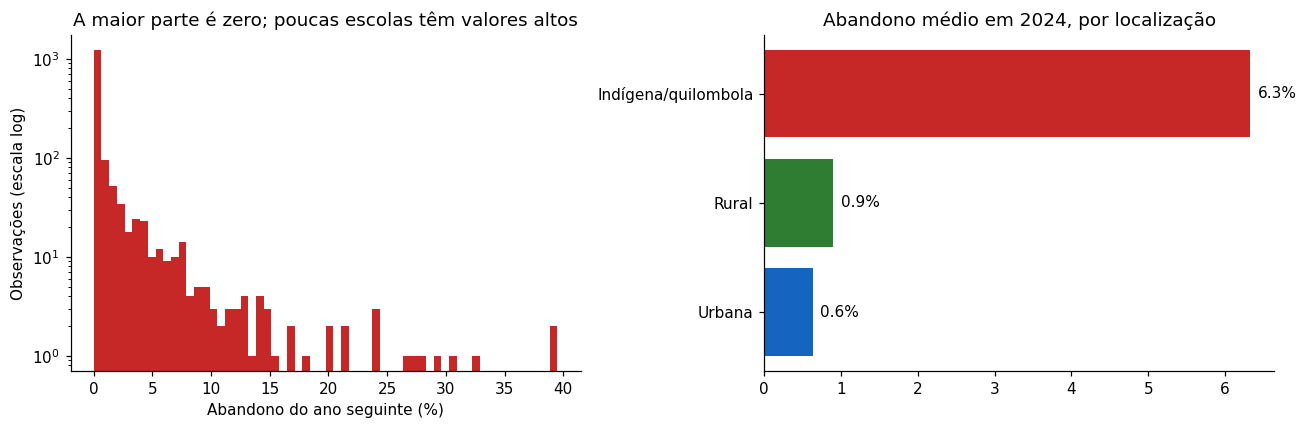

In [4]:
y = df[TARGET_COL]
print(f"Observações com abandono zero: {(y == 0).mean():.0%}")
print(f"Observações acima de 10%:      {(y > 10).mean():.0%}")
print("Abandono médio do ano seguinte:",
      {f"{a}→{a + 1}": f"{v:.2f}%" for a, v in df.groupby(ANO_COL)[TARGET_COL].mean().items()})

# Abandono de 2024 por localização (diferenciada = qualquer código de localização diferenciada)
loc = painel.loc[painel.NU_ANO_CENSO == 2024, ["CO_ENTIDADE", "TP_LOCALIZACAO", "TP_LOCALIZACAO_DIFERENCIADA"]]
d = taxas[taxas.NU_ANO_CENSO == 2024].merge(loc, on="CO_ENTIDADE")
d["grupo"] = np.where(d.TP_LOCALIZACAO_DIFERENCIADA.fillna(0) > 0, "Indígena/quilombola",
                      np.where(d.TP_LOCALIZACAO == 2, "Rural", "Urbana"))
por_loc = d.groupby("grupo")["TAXA_ABND_MED"].agg(escolas="size", abandono_medio="mean")
display(por_loc.sort_values("abandono_medio"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.hist(y, bins=60, color=VERMELHO); a1.set_yscale("log")
a1.set_xlabel("Abandono do ano seguinte (%)"); a1.set_ylabel("Observações (escala log)")
a1.set_title("A maior parte é zero; poucas escolas têm valores altos")
s = por_loc.sort_values("abandono_medio")
a2.barh(s.index, s.abandono_medio, color=[AZUL, VERDE, VERMELHO])
for i, v in enumerate(s.abandono_medio):
    a2.text(v + 0.1, i, f"{v:.1f}%", va="center")
a2.set_title("Abandono médio em 2024, por localização")
plt.tight_layout(); plt.show()

## 4. As 39 características em 6 grupos

A lista vem da própria função que monta o conjunto (`_colunas_features()` em `src/features/build_features.py`). Os rótulos são os mesmos que o painel mostra ao gestor (`src/recommend/labels.py`).

In [5]:
from src.recommend.labels import rotular_feature

GRUPOS = {
    "Contexto e localização": ["is_rural", "is_loc_diferenciada", "CO_MESORREGIAO", "oferta_em_nao_seriado"],
    "Porte e proporções": ["log_mat_med", "alunos_por_turma", "alunos_por_docente",
                           "computadores_por_aluno", "pct_integral"],
    "Infraestrutura": [c for c in features if c.startswith("IN_")] + ["indice_infra"],
    "Corpo docente": ["ird_med_t", "afd_g1_t", "afd_g3_t", "afd_g5_t"],
    "Perfil dos alunos": ["inse_media", "tdi_med_t", "tdi_s1_t", "tdi_s2_t", "tdi_s3_t"],
    "Histórico de rendimento": ["abnd_t", "abnd_s1_t", "abnd_s2_t", "abnd_s3_t",
                                "reprov_t", "reprov_s1_t", "reprov_s2_t", "reprov_s3_t"],
}
assert sorted(sum(GRUPOS.values(), [])) == sorted(features), "grupos não cobrem as 39"

for grupo, cols in GRUPOS.items():
    print(f"\n{grupo} ({len(cols)})")
    for c in cols:
        print(f"   - {rotular_feature(c)}")
print(f"\nTotal: {sum(len(c) for c in GRUPOS.values())} características")


Contexto e localização (4)
   - Localização rural
   - Localização diferenciada (indígena/quilombola)
   - Mesorregião
   - Oferta de EM fora das séries regulares (EJA/modular)

Porte e proporções (5)
   - Porte (logaritmo do nº de matrículas)
   - Alunos por turma
   - Alunos por docente
   - Computadores por aluno
   - % de matrículas em tempo integral

Infraestrutura (13)
   - Água potável
   - Esgoto em rede pública
   - Biblioteca
   - Laboratório de ciências
   - Laboratório de informática
   - Quadra de esportes
   - Refeitório
   - Sala de leitura
   - Auditório
   - Internet
   - Internet para alunos
   - Banda larga
   - Índice de infraestrutura

Corpo docente (4)
   - Regularidade do corpo docente (IRD)
   - Adequação da formação docente — Grupo 1
   - Adequação da formação docente — Grupo 3
   - Adequação da formação docente — Grupo 5

Perfil dos alunos (5)
   - Nível socioeconômico (INSE)
   - Distorção idade-série (Ensino Médio)
   - Distorção idade-série — 1ª série
   -

## 5. Relação de cada característica com o abandono do ano seguinte

Correlação de Spearman entre cada característica numérica e o abandono de t+1, calculada agora. A mesorregião é categórica e fica de fora, por isso são 38.

30 de 38 têm relação estatisticamente significativa (p < 0,05)


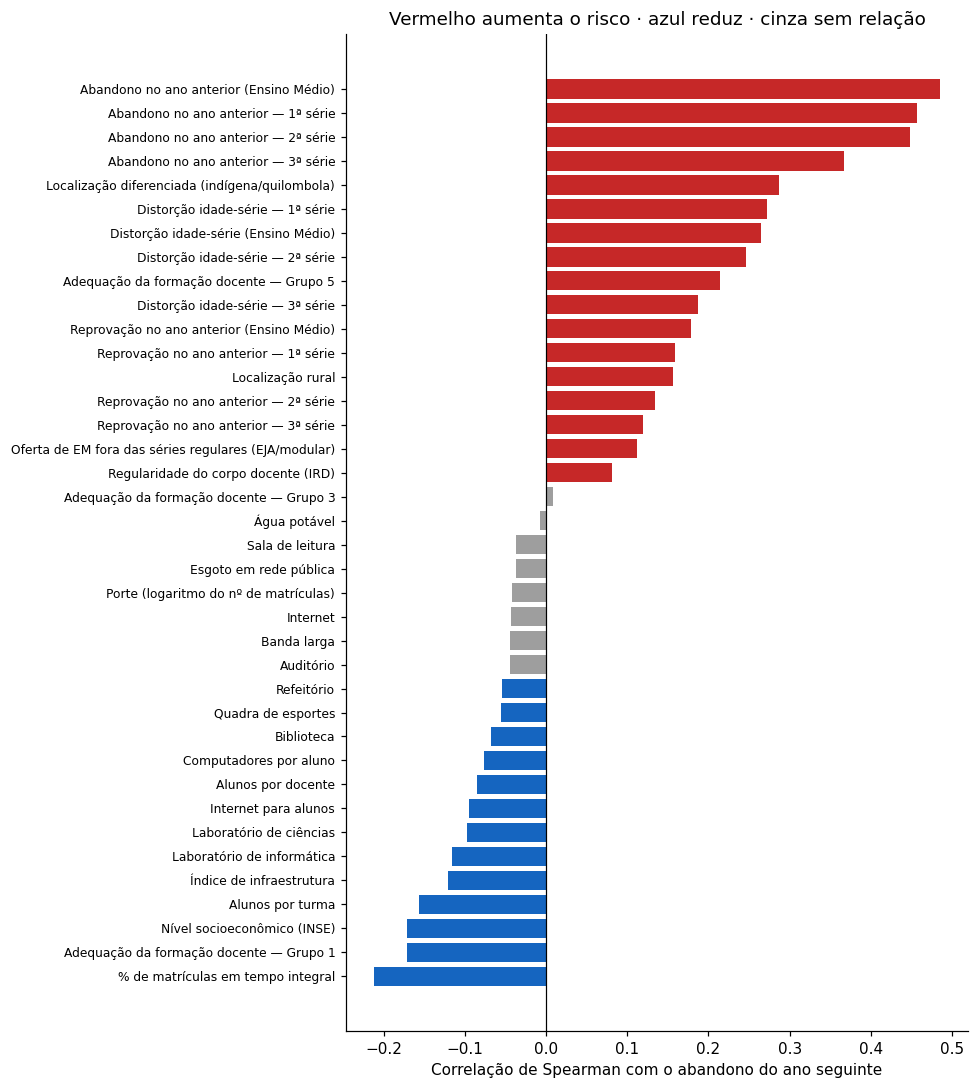

In [6]:
from scipy.stats import spearmanr

linhas = []
for c in features:
    if c == "CO_MESORREGIAO":
        continue
    rho, p = spearmanr(df[c], df[TARGET_COL])
    linhas.append({"característica": rotular_feature(c), "rho": rho, "p": p})
rel = pd.DataFrame(linhas).sort_values("rho")
sig = rel["p"] < 0.05
print(f"{sig.sum()} de {len(rel)} têm relação estatisticamente significativa (p < 0,05)")

fig, ax = plt.subplots(figsize=(9, 10))
cores = np.where(~sig, CINZA, np.where(rel["rho"] > 0, VERMELHO, AZUL))
ax.barh(rel["característica"], rel["rho"], color=cores)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Correlação de Spearman com o abandono do ano seguinte")
ax.set_title("Vermelho aumenta o risco · azul reduz · cinza sem relação")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

## 6. Os testes que travam o pipeline

Em um sistema que aprende com dados, o erro não quebra a execução: gera, em silêncio, um modelo inválido. Os testes cobrem riscos de **validade**: casamento temporal t→t+1, vazamento de município entre treino e teste, aditividade do SHAP e a cadeia 2.392 → 1.586.

In [7]:
import subprocess
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider"],
                   cwd=ROOT, capture_output=True, text=True)
print(r.stdout[-600:])

........................................................................ [ 52%]
..................................................................       [100%]
138 passed in 4.63s

